In [1]:
import sys

# this kernel's numpy (2.1.2) + uproot (5.1.2) combo raises OverflowError reading JetClass
# .root files - prepend the deps folder with compatible versions before anything imports numpy
deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import pyrootutils

pyrootutils.setup_root(__file__ if "__file__" in dir() else ".", indicator=".project-root", pythonpath=True)

import hydra
import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from gabbro.models.backbone_multihead import BackboneMultiHeadLightning

from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

# load aoj dataset

In [ ]:
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg_aoj = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_ntp_classifier_head",
            "feature_dict=feature_dict_all_without_cuts",
        ],
    )

AOJ_FILE = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets/RunG_batch0.h5"

# switch off the tokenized-parquet codepath and jetclass-only extras, point at the AOJ file
cfg_aoj.data.dataset_kwargs_common.dataset_type = "aoj"
cfg_aoj.data.dataset_kwargs_common.token_id_cfg = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_labels_particles = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_jet = None
cfg_aoj.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

cfg_aoj.data.data_dir = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets"
# `setup(stage="fit")` also builds the val dataset, so point that at the same single file too
cfg_aoj.data.dataset_kwargs_train.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_train.max_n_files_per_type = 1
cfg_aoj.data.dataset_kwargs_val.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_val.max_n_files_per_type = 1

# disable all shuffling so batch order is just the file's on-disk order, identical every run
for split in ["train", "val", "test"]:
    cfg_aoj.data[f"dataset_kwargs_{split}"].shuffle_files = False
    cfg_aoj.data[f"dataset_kwargs_{split}"].shuffle_data = False

print(OmegaConf.to_yaml(cfg_aoj.data.dataset_kwargs_common.feature_dict, resolve=True))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [3]:
datamodule_aoj = hydra.utils.instantiate(cfg_aoj.data)
# AOJ has no separate train/val/test split - just read the file(s) directly
datamodule_aoj.setup(stage="fit")

train_dataloader_aoj = datamodule_aoj.train_dataloader()

Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
n_files_at_once=10 is larger than the number of files in the dataset (1).
Setting n_files_at_once to 1.
shuffle_files is False. This means

n_files_at_once=10 is larger than the number of files in the dataset (1).
Setting n_files_at_once to 1.


# load ntp model

In [4]:
CKPT_PATH = (
    "/home/users/w/wozniak/dev/enhancing-ntp4jets/trained/omnijet-backbone-multihead-allfeat-ntp-classifier-head/runs/2026-08-29_03-54-46_gpu023_UngussetedHandsaw/checkpoints/last.ckpt"
)

# Load the *resolved* config that was actually used to train this checkpoint (saved next to the
# run's checkpoints directory), instead of re-composing from the current experiment yaml. This
# matters because the experiment yaml can change over time (e.g. the `feature_dict` override in
# `example_experiment_backbone_and_head.yaml` has since been changed to the extended/all-features
# set), while this specific checkpoint was trained with a different feature_dict
# (`feature_dict_kin_massless_without_cuts.yaml`). Using the checkpoint's own resolved config
# guarantees the preprocessing/feature_dict/tokenization match what the model was actually trained on.
from pathlib import Path

resolved_cfg_path = Path(CKPT_PATH).parent.parent / "config_resolved.yaml"
cfg = OmegaConf.load(resolved_cfg_path)

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [5]:
model_ntp = BackboneMultiHeadLightning.load_from_checkpoint(CKPT_PATH, map_location=device)
model_ntp = model_ntp.to(device)
model_ntp.eval()

print(f"head_mpm is active: {model_ntp.head_mpm is not None}")
print(f"head_gen is active: {model_ntp.head_gen is not None}")
print(f"head_class is active: {model_ntp.head_class is not None}")

NOT applying causal mask in the attention blocks. If you are using this model for an autoregressive generative task, this is probably not what you want.


head_mpm is active: False
head_gen is active: False
head_class is active: True


In [6]:
ntp_backbone_out_list = []
ntp_part_mask_list = []
ntp_logits_gen_list = []
ntp_logits_mpm_list = []
ntp_logits_class_list = []

with torch.no_grad():
    for i, batch in enumerate(train_dataloader_aoj):
        if i >= 10:
            break

        part_features = batch["part_features"].to(device)
        part_mask = batch["part_mask"].to(device).int()

        # AOJ isn't tokenized, so unlike JetClass there's no reserved all-zero slot at
        # position 0 - prepend the learned start token as an extra particle instead.
        # Truncate to leave room for it, since the model's max_sequence_len (and the
        # size of masked_feature_vector) doesn't allow for a longer sequence.
        if model_ntp.hparams.start_token_type in ["trainable", "zero_pad"]:
            batch_size = part_features.shape[0]
            part_features = part_features[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            part_mask = part_mask[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            start_token = model_ntp.start_token_continuous.unsqueeze(0).repeat(batch_size, 1, 1)
            part_features = torch.cat([start_token, part_features], dim=1)
            start_mask = torch.ones(batch_size, 1, dtype=part_mask.dtype, device=device)
            part_mask = torch.cat([start_mask, part_mask], dim=1)

        # `model.forward()` only returns head logits, not the backbone's last-layer
        # representation - call the backbone module itself to get that
        backbone_out = model_ntp.backbone(part_features, mask=part_mask)
        ntp_backbone_out_list.append(backbone_out.cpu())
        ntp_part_mask_list.append(part_mask.cpu())

        logits_gen, logits_mpm, logits_class = model_ntp(
            part_features, valid_particle_mask=part_mask
        )

        if logits_gen is not None:
            ntp_logits_gen_list.append(logits_gen.cpu())
        if logits_mpm is not None:
            ntp_logits_mpm_list.append(logits_mpm.cpu())
        if logits_class is not None:
            ntp_logits_class_list.append(logits_class.cpu())

print(f"Ran inference on {len(ntp_logits_class_list)} batches.")

You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.


Ran inference on 10 batches.


## load mpm model

## 

In [7]:
CKPT_PATH = (
    "/home/users/w/wozniak/dev/enhancing-ntp4jets/trained/omnijet-backbone-multihead-allfeat-mpm-classifier-head/runs/2026-08-21_15-06-12_gpu024_TympanicAnkylosis/checkpoints/last.ckpt"
)

# Load the *resolved* config that was actually used to train this checkpoint (saved next to the
# run's checkpoints directory), instead of re-composing from the current experiment yaml. This
# matters because the experiment yaml can change over time (e.g. the `feature_dict` override in
# `example_experiment_backbone_and_head.yaml` has since been changed to the extended/all-features
# set), while this specific checkpoint was trained with a different feature_dict
# (`feature_dict_kin_massless_without_cuts.yaml`). Using the checkpoint's own resolved config
# guarantees the preprocessing/feature_dict/tokenization match what the model was actually trained on.
from pathlib import Path

resolved_cfg_path = Path(CKPT_PATH).parent.parent / "config_resolved.yaml"
cfg = OmegaConf.load(resolved_cfg_path)

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict))

The history saving thread hit an unexpected error (OperationalError('disk I/O error')).History will not be written to the database.
part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [8]:
model_mpm = BackboneMultiHeadLightning.load_from_checkpoint(CKPT_PATH, map_location=device)
model_mpm = model_mpm.to(device)
model_mpm.eval()

print(f"head_mpm is active: {model_mpm.head_mpm is not None}")
print(f"head_gen is active: {model_mpm.head_gen is not None}")
print(f"head_class is active: {model_mpm.head_class is not None}")

NOT applying causal mask in the attention blocks. If you are using this model for an autoregressive generative task, this is probably not what you want.


head_mpm is active: False
head_gen is active: False
head_class is active: True


In [9]:
mpm_backbone_out_list = []
mpm_part_mask_list = []
mpm_logits_gen_list = []
mpm_logits_mpm_list = []
mpm_logits_class_list = []

with torch.no_grad():
    for i, batch in enumerate(train_dataloader_aoj):
        if i >= 10:
            break

        part_features = batch["part_features"].to(device)
        part_mask = batch["part_mask"].to(device).int()

        # AOJ isn't tokenized, so unlike JetClass there's no reserved all-zero slot at
        # position 0 - prepend the learned start token as an extra particle instead.
        # Truncate to leave room for it, since the model's max_sequence_len (and the
        # size of masked_feature_vector) doesn't allow for a longer sequence.
        if model_mpm.hparams.start_token_type in ["trainable", "zero_pad"]:
            batch_size = part_features.shape[0]
            part_features = part_features[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            part_mask = part_mask[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            start_token = model_mpm.start_token_continuous.unsqueeze(0).repeat(batch_size, 1, 1)
            part_features = torch.cat([start_token, part_features], dim=1)
            start_mask = torch.ones(batch_size, 1, dtype=part_mask.dtype, device=device)
            part_mask = torch.cat([start_mask, part_mask], dim=1)

        # `model.forward()` only returns head logits, not the backbone's last-layer
        # representation - call the backbone module itself to get that
        mpm_backbone_out = model_mpm.backbone(part_features, mask=part_mask)
        mpm_backbone_out_list.append(mpm_backbone_out.cpu())
        mpm_part_mask_list.append(part_mask.cpu())

        logits_gen, logits_mpm, logits_class = model_mpm(
            part_features, valid_particle_mask=part_mask
        )

        if logits_gen is not None:
            mpm_logits_gen_list.append(logits_gen.cpu())
        if logits_mpm is not None:
            mpm_logits_mpm_list.append(logits_mpm.cpu())
        if logits_class is not None:
            mpm_logits_class_list.append(logits_class.cpu())
print(f"Ran inference on {len(mpm_logits_class_list)} batches.")

You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.


Ran inference on 10 batches.


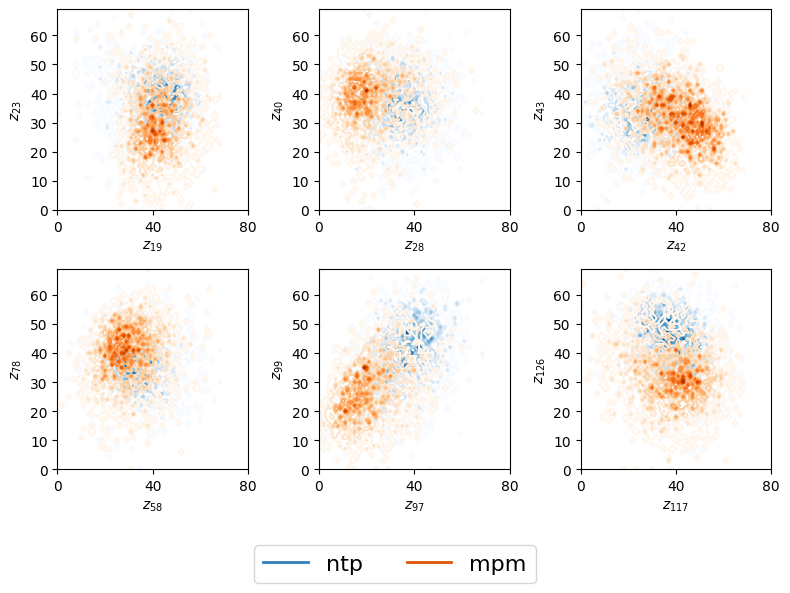

writing figure to analysis/aoj_inference/latent_space_2D_hist.png
Saved plot to analysis/aoj_inference


In [45]:
import os

from gabbro.utils.plotting_utils import plot_latent_space_2D_for_two_samples
import importlib

import gabbro.utils.plotting_utils as plotting_utils

importlib.reload(plotting_utils)


def mean_pool_backbone_out(backbone_out_list, mask_list):
    """Mean-pool per-particle backbone output over valid (non-padded) particles per jet."""
    reps = []
    for backbone_out, mask in zip(backbone_out_list, mask_list):
        mask = mask.float().unsqueeze(-1)
        summed = (backbone_out * mask).sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1)
        reps.append(summed / counts)
    return torch.cat(reps).numpy()


latent_ntp = mean_pool_backbone_out(ntp_backbone_out_list, ntp_part_mask_list)
latent_mpm = mean_pool_backbone_out(mpm_backbone_out_list, mpm_part_mask_list)

output_dir = "analysis/aoj_inference"
os.makedirs(output_dir, exist_ok=True)

# ntp = background, mpm = signal
plot_latent_space_2D_for_two_samples(
    latent_bg=latent_ntp,
    latent_sig=latent_mpm,
    n_dims=12,
    title_suffix="ntp vs mpm representations",
    filename_suffix="ntp_vs_mpm_backbone",
    fig_dir=output_dir,
    show_plot=True,
    legend_outside=True,
    fig_size=(8, 6),
    sample_names=["ntp", "mpm"]
)
print(f"Saved plot to {output_dir}")